In [1]:
import pandas as pd

df = pd.read_csv("../../data/processed/netflix_cleaned.csv")
df["type"].value_counts()

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

In [2]:
(df["type"].value_counts(normalize=True) * 100).round(2)

type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64

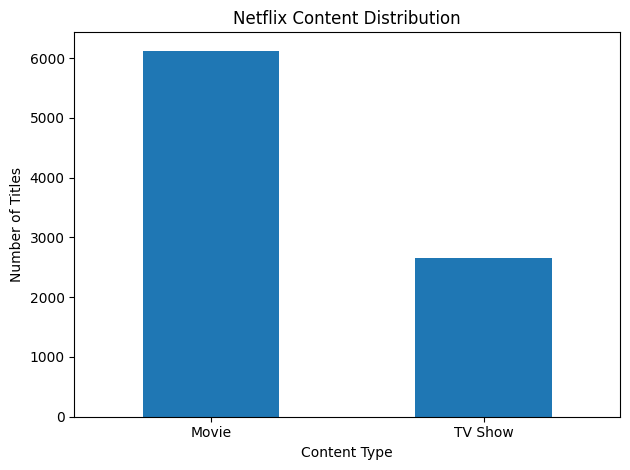

In [3]:
import matplotlib.pyplot as plt

df["type"].value_counts().plot(kind="bar", rot=0)
plt.title("Netflix Content Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig("../outputs/content_distribution.png")
plt.show()

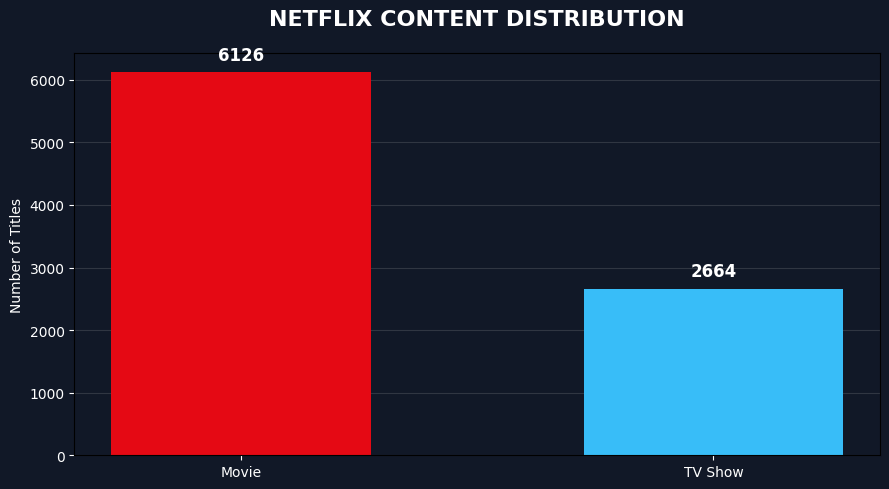

In [4]:
import matplotlib.pyplot as plt

counts = df["type"].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor("#111827")
ax.set_facecolor("#111827")

bars = ax.bar(
    counts.index, counts.values,
    color=["#E50914", "#38BDF8"], width=0.55
)

ax.bar_label(bars, fmt="%d", padding=6,
             color="white", fontsize=12, fontweight="bold")

ax.set_title("NETFLIX CONTENT DISTRIBUTION",
             color="white", fontsize=16, fontweight="bold", pad=20)
ax.set_ylabel("Number of Titles", color="white")
ax.tick_params(colors="white")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("../outputs/content_distribution.png",
            dpi=300, facecolor=fig.get_facecolor())
plt.show()

In [5]:
import plotly.express as px

fig = px.pie(
    df,
    names="type",
    color_discrete_sequence=px.colors.sequential.RdBu,
    template="plotly_dark",
    height=400,
    width=400,
    title="Netflix Content Distribution"
)

fig.update_traces(
    textposition="inside",
    textinfo="percent+label"
)

fig.write_html("../outputs/content_distribution.html")
fig.show()

In [6]:
counts = df["type"].value_counts()

fig = px.bar(
    x=counts.index, y=counts.values,
    color=counts.index,
    color_discrete_sequence=px.colors.sequential.RdBu,
    template="plotly_dark",
    height=400, width=700,
    title="Movies vs TV Shows"
)

fig.update_traces(texttemplate="%{y:,}", textposition="outside")
fig.write_html("../outputs/content_comparison.html")
fig.show()

In [7]:
fig = px.pie(
    df, names="type", hole=0.55,
    color_discrete_sequence=px.colors.sequential.RdBu,
    template="plotly_dark", height=450, width=650,
    title="Netflix Content Share"
)

fig.update_traces(textposition="inside", textinfo="percent+label")
fig.write_html("../outputs/content_share_donut.html")
fig.show()

In [8]:
counts = df["type"].value_counts().rename_axis("Content Type").reset_index(name="Titles")

fig = px.treemap(
    counts,
    path=["Content Type"],
    values="Titles",
    color="Titles",
    color_continuous_scale=px.colors.sequential.RdBu,
    template="plotly_dark",
    height=450,
    width=700,
    title="Netflix Catalog Composition"
)

fig.write_html("../outputs/content_treemap.html")
fig.show()

In [9]:
share = (df["type"].value_counts(normalize=True) * 100).reset_index()
share.columns = ["Content Type", "Percentage"]

fig = px.bar(
    share, x="Content Type", y="Percentage",
    color="Percentage",
    color_continuous_scale=px.colors.sequential.RdBu,
    template="plotly_dark",
    text="Percentage",
    height=450, width=700,
    title="Netflix Content Type — Percentage Share"
)

fig.update_traces(texttemplate="%{text:.2f}%", textposition="outside")
fig.write_html("../outputs/content_percentage.html")
fig.show()

In [10]:
fig = px.bar(
    df["type"].value_counts().reset_index(),
    x="count", y="type", orientation="h",
    color="type",
    color_discrete_sequence=px.colors.sequential.RdBu,
    template="plotly_dark", height=400, width=700,
    title="Netflix Content Distribution"
)

fig.update_traces(texttemplate="%{x:,}", textposition="outside")
fig.write_html("../outputs/content_horizontal_bar.html")
fig.show()

In [11]:
counts = df["type"].value_counts()
percentages = (df["type"].value_counts(normalize=True) * 100).round(2)

print(f"Movies: {counts['Movie']:,} ({percentages['Movie']}%)")
print(f"TV Shows: {counts['TV Show']:,} ({percentages['TV Show']}%)")
print("Insight: Movies make up the majority of the Netflix dataset.")

Movies: 6,126 (69.69%)
TV Shows: 2,664 (30.31%)
Insight: Movies make up the majority of the Netflix dataset.
